# PakFreight — Week 5 ETL Assignment
**Completed Python / Jupyter track · Tasks T1–T7 and practical lab**

This notebook contains the written answers, executable pipeline, intermediate step snapshots, source audit, baseline checks and unseen-file refresh test. All original uploads are preserved in `original_files/`; the supplied student workbook remains unchanged because the requested answer format is `.ipynb`.

Run all cells from this folder. Only local files are needed. `pipeline.py` is the standalone equivalent. Team and roll number were not supplied; filenames therefore use the assignment name.

**Interpretation notes:** the seven-column contract is checked **before** adding ModeKey (eight columns afterwards). Raw rail data has ten records plus two title rows and a header; its untouched byte copy preserves all of them. Road's extract count includes the blank and TOTAL records; its 83,000 kg subtotal excludes the footer but includes the duplicate. The guide contains shorthand inconsistencies (sixteen versus seventeen steps; dates called quiet despite one parsing error); the detailed workbook classifications and seventeen-step task govern the answers.

## T1 — Defect census
| # | Defect | Class | Step | Verdict | Consequence if ignored |
|---|---|---|---|---|---|
|1|Different headers|Structural|RenameToContract|Quiet|Append unions names into 20 columns; facts become sparse.|
|2|Rail title rows|Structural|SkippedTitleRows → PromotedHeaders|Loud|Expected column names cannot be found by later steps.|
|3|Rail tons|Type & Unit|ConvertUnitsSetTypes|Quiet|295.25 is treated as kg; total understates by 294,954.75 kg.|
|4|Date representations / ambiguous marine dates|Type & Unit|ParseDatesExplicitly|Both|US parsing misplaces ten dates, happens to get one right and errors on the thirteenth.|
|5|Leading/trailing spaces|String|TrimCleanText|Quiet|Values fail equality checks, split groups or evade deduplication.|
|6|Status casing|String|NormalizeStatus|Quiet|Seventeen raw strings do not group into three business states.|
|7|City aliases|Conform|ConformKeys|Quiet|Cities fragment or become unmatched; only business knowledge resolves aliases.|
|8|Blank and TOTAL road rows|Structural|RemovedBlankRows; RemovedTotalRow|Quiet|Blank inflates count; footer adds another 83,000 kg and PKR 652,000 if retained.|
|9|Repeated rd-505|Conform|DeduplicateShipmentID|Quiet|One shipment counts twice: +6,100 kg and +PKR 47,000.|
|10|No mode field|Conform / enrichment|AddModeKey|Not a defect|Mode is known from the source; derive it rather than expect a missing source field.|

**Counts:** 1 Loud, 7 Quiet, 1 Both, 1 Not a defect. These classifications describe the lab's ignored-defect scenario; strict parsing could surface junk rows earlier.

Row 10 tests whether absence is distinguished from erroneous data. Rows 8 and 9 require a grain decision: the fact represents one shipment, so a summary footer is not a shipment and a repeated business key is not a second shipment. These are business judgements, not malformed syntax. An equal ID with different payload must be investigated rather than arbitrarily discarded.

## T2 — Stage ownership
| # | Activity | Verdict | Reason |
|---|---|---|---|
|1|Connect/read named rail sheet|Extract|Read the source without correcting it.|
|2|Strip status while reading|Violation|Extract must not clean; preserve evidence first.|
|3|Log source row counts|Extract|Record lineage and completeness.|
|4|Promote rail row 3|Transform|Reshape a landed copy.|
|5|Correct railway operational database|Violation|Transform must never write to the source.|
|6|Multiply tons by 1,000|Transform|Conform measurement units.|
|7|Interpret Port Qasim as Karachi|Transform|Apply a business alias mapping.|
|8|Unmatched city → -1|Transform|Resolve keys under an explicit Unknown policy.|
|9|Independent dimensions before facts|Load|Respect dependencies.|
|10|Decide blank-status handling while writing|Violation|Load must execute decisions already made by transform.|
|11|All six writes or none|Load|Commit or roll back the consistent star.|
|12|Publish staging to sales|Violation|Expose only validated, conformed data.|

**Counts:** Extract 2; Transform 4; Load 2; Violation 4.

Staging may contain mixed units, duplicate business keys, partial files and unresolved values. Publishing it bypasses the validation boundary and creates competing versions of truth. In Power Query, disable **Enable load** on staging queries (Excel: **Only Create Connection**). Here raw frames, per-source frames, `AliasLookup`, and `FactStaging` are intermediate; only the five dimensions and validated `FactShipment` are published tables. Audit CSVs are diagnostic evidence, not additional star tables.

## T3 — Seventeen steps in execution order
|Order|Step|Stage|Cadence|Defects / purpose|Why here|
|---|---|---|---|---|---|
|1|Connect to sources|Extract|per source|Access|Before reading.|
|2|Land unchanged copy|Extract|per source|Evidence|Before any modification.|
|3|Log source, time, count|Extract|per source|Audit|Record the original arrival.|
|4|Promote headers; drop junk|Transform|per source|2, 8|Establish record shape.|
|5|Rename to contract|Transform|per source|1|Align names before concatenation.|
|6|Trim and clean text|Transform|per source|5; supports 7, 9|Establish comparable values; uppercase IDs and prefix rail IDs.|
|7|Normalize status casing|Transform|per source|6|Collapse case after whitespace normalization.|
|8|Parse explicit date formats|Transform|per source|4|Source-specific interpretation is still available.|
|9|Convert rail tons; set types|Transform|per source|3|Apply units before source context is combined.|
|10|Add ModeKey|Transform|per source|10 enrichment|Source determines mode.|
|11|Append|Transform|once|Combine|All sources now share schema and units.|
|12|Deduplicate ShipmentID|Transform|once|9|Compare canonical business keys globally.|
|13|Conform names / keys; unknown → -1|Transform|once|7|Use left joins without losing shipments.|
|14|Load four independent dimensions|Load|once|Date, City, Mode, Status|Parents first.|
|15|Load DimRoute|Load|once|Route depends on City|Before the referencing fact.|
|16|Load FactShipment|Load|once|Validated shipment grain|Dimensions exist.|
|17|Reconcile or fail|Load|once|Publication gate|Validate inside transaction before commit.|

**Counts:** 3 Extract + 10 Transform + 4 Load; 10 per source + 7 once. The executable `STEPS` list names these logical phases. Physical snapshots split source-specific operations so blank/footer filters exist only for road.

|Constraint|Before → after|Measured cost of violation|Reason|
|---|---|---|---|
|Rename before append|5 → 11|20 original columns rather than 7 contract fields|Only Status is shared across the raw schemas.|
|Trim before deduplicate|6 → 12|Night two: 36 rows / 591,550 kg instead of 35 / 584,950 kg|The status-space copy survives early whole-row comparison; ID-only dedup still works on these fixtures.|
|Convert before append|9 → 11|283,695.25 kg rather than 578,650 kg|295.25 tons cannot be summed as 295.25 kg.|

Night one's two `rd-505` records are byte-identical, so an early dedup accidentally succeeds: 34 rows, 578,650 kg. That does not prove the order safe. Duplicates are defined by **normalized ShipmentID**, not raw spelling or all-column equality. The night-two whitespace variant exposes a whole-row-comparison failure, not an ID-only failure: its trailing space is in status, and both raw IDs are identical. Normalizing identifiers first is still the general rule for future ID whitespace variants. Equivalent duplicate payloads are removed; conflicting payloads stop this implementation for review.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 160)

In [2]:
"""Repeatable PakFreight Python track. All raw/intermediate frames are private staging."""
from pathlib import Path
from datetime import datetime, timezone
import hashlib, shutil, sqlite3
import pandas as pd
ROOT = Path.cwd()
CONTRACT = ['ShipmentID','ShipDate','OriginRaw','DestRaw','WeightKG','FreightCostPKR','StatusRaw']
HEADERS = {
 'marine':['Shipment_ID','Ship_Date','Origin_Port','Dest_Port','Weight_KG','Cost_PKR','Status'],
 'road':['trip_id','trip_date','from_city','to_city','weight_kg','cost_pkr','status'],
 'rail':['Consignment No','Dispatch Date','From Station','To Station','Weight (Tons)','Freight Charges (PKR)','Status']}
MODE = {'marine':1,'rail':2,'road':3}
# Ordered logical design. Physical source steps below preserve inspectable snapshots.
STEPS = ['ConnectSources','LandFaithfulCopy','LogExtraction','ShapeTables','RenameToContract',
         'TrimCleanText','NormalizeStatus','ParseDatesExplicitly','ConvertUnitsSetTypes',
         'AddModeKey','AppendSources','DeduplicateShipmentID','ConformKeys',
         'LoadIndependentDimensions','LoadDimRoute','LoadFactShipment','ReconcileOrRollback']

def pipeline(source, run_name):
    source=Path(source); frames={}; logs=[]; parts={}
    landing=ROOT/'outputs'/'staging'/run_name; landing.mkdir(parents=True,exist_ok=True)
    def keep(name,df): frames[name]=df.copy(deep=True); return df
    for name in ('marine','rail','road'):
        ext='xlsx' if name=='rail' else 'csv'; path=source/f'{name}_shipments.{ext}'
        landed=landing/path.name
        shutil.copyfile(path,landed) # byte-for-byte copy: extraction changes nothing
        digest=hashlib.sha256(path.read_bytes()).hexdigest()
        assert digest==hashlib.sha256(landed.read_bytes()).hexdigest()
        raw=(pd.read_excel(landed,sheet_name='Rail',header=None) if name=='rail'
             else pd.read_csv(landed,header=None,skip_blank_lines=False))
        keep(f'{name}.Source',raw)
        count=len(raw)-(3 if name=='rail' else 1)
        logs.append({'source':path.name,'utc':datetime.now(timezone.utc).isoformat(),'rows_landed':count,'sha256':digest})
        if name=='rail': raw=keep('rail.SkippedTitleRows',raw.iloc[2:].reset_index(drop=True))
        df=raw.iloc[1:].copy(); df.columns=raw.iloc[0].tolist(); df=df.reset_index(drop=True)
        keep(f'{name}.PromotedHeaders',df)
        assert list(df.columns)==HEADERS[name], f'Unexpected schema: {name}'
        if name=='road':
            df=keep('road.RemovedBlankRows',df.loc[~df.isna().all(axis=1)].copy())
            df=keep('road.RemovedTotalRow',df.loc[df.trip_id.astype('string').str.strip().str.upper()!='TOTAL'].copy())
        df=keep(f'{name}.RenamedToContract',df.rename(columns=dict(zip(HEADERS[name],CONTRACT))))
        for c in CONTRACT:
            if c not in ['ShipDate','WeightKG','FreightCostPKR']:
                df[c]=df[c].astype('string').str.replace(r'\s+',' ',regex=True).str.replace(r'[\x00-\x1f]','',regex=True).str.strip()
        df.ShipmentID=df.ShipmentID.str.upper()
        if name=='rail': df.ShipmentID='RL-'+pd.to_numeric(df.ShipmentID).astype('int64').astype(str)
        keep(f'{name}.TrimmedCleanedText',df)
        df.StatusRaw=df.StatusRaw.str.title(); keep(f'{name}.NormalizedStatus',df)
        if name=='marine': df.ShipDate=pd.to_datetime(df.ShipDate,format='%d/%m/%Y',errors='raise')
        elif name=='road': df.ShipDate=pd.to_datetime(df.ShipDate,format='%Y-%m-%d',errors='raise')
        else: df.ShipDate=pd.to_datetime(df.ShipDate,errors='raise') # native Excel dates
        keep(f'{name}.ParsedDates',df)
        for c in ['WeightKG','FreightCostPKR']: df[c]=pd.to_numeric(df[c],errors='raise')
        if name=='rail': df.WeightKG=df.WeightKG*1000
        for c in ['WeightKG','FreightCostPKR']:
            assert (df[c]%1==0).all(); df[c]=df[c].astype('int64')
        keep(f'{name}.ConvertedUnitsSetTypes',df)
        assert list(df.columns)==CONTRACT # seven BEFORE derived ModeKey
        df['ModeKey']=MODE[name]; parts[name]=keep(f'{name}.AddedModeKey',df)
    dims={n:pd.read_csv(ROOT/'data/dims'/f'{n}.csv') for n in ['DimDate','DimCity','DimMode','DimStatus','DimRoute']}
    alias=(dims['DimCity'][['CityKey','CityName','RawAliases']].assign(RawAliases=lambda d:d.RawAliases.str.split(' | ',regex=False)).explode('RawAliases').dropna(subset=['RawAliases']).rename(columns={'RawAliases':'RawSpelling'}))
    alias.RawSpelling=alias.RawSpelling.str.strip(); alias=alias[alias.RawSpelling.ne('')]
    assert len(alias)==23 and alias.CityKey.nunique()==14 and alias.RawSpelling.is_unique
    keep('AliasLookup',alias)
    fact=keep('Appended',pd.concat(parts.values(),ignore_index=True))
    duplicates=fact[fact.duplicated('ShipmentID',keep=False)].copy()
    for _, group in duplicates.groupby('ShipmentID'):
        assert len(group.drop_duplicates())==1, 'Conflicting duplicate: manual business review required'
    fact=keep('Deduplicated',fact.drop_duplicates(subset=['ShipmentID']).copy())
    for raw,key in [('OriginRaw','OriginCityKey'),('DestRaw','DestCityKey')]:
        fact=fact.merge(alias[['RawSpelling','CityKey']].rename(columns={'RawSpelling':raw,'CityKey':key}),on=raw,how='left',validate='many_to_one')
        fact[key]=fact[key].fillna(-1).astype('int64'); keep(f'Conformed{key}',fact)
    unknown=fact.loc[(fact.OriginCityKey==-1)|(fact.DestCityKey==-1)].copy()
    dates=dims['DimDate'][['DateKey','FullDate']].copy(); dates['ShipDate']=pd.to_datetime(dates.pop('FullDate'),format='%Y-%m-%d')
    fact=fact.merge(dates,on='ShipDate',how='left',validate='many_to_one')
    assert fact.DateKey.notna().all(), 'Date outside supplied dimension'
    fact=fact.merge(dims['DimStatus'][['StatusKey','StatusName']],left_on='StatusRaw',right_on='StatusName',how='left',validate='many_to_one').drop(columns='StatusName')
    fact.StatusKey=fact.StatusKey.fillna(-1).astype('int64')
    fact=fact.merge(dims['DimRoute'][['RouteKey','OriginCityKey','DestCityKey']],on=['OriginCityKey','DestCityKey'],how='left',validate='many_to_one')
    fact.RouteKey=fact.RouteKey.fillna(-1).astype('int64')
    keep('FactStaging',fact)
    return dict(fact=fact,parts=parts,frames=frames,log=pd.DataFrame(logs),alias=alias,dims=dims,unknown=unknown,duplicates=duplicates)

def checks(run,night=1):
    f=run['fact']; expected=[7,295250,3,'2026-02-13',34 if night==1 else 35,0 if night==1 else 1,578650 if night==1 else 584950,4808000 if night==1 else 4860000]
    actual=[7 if all(list(run['frames'][f'{n}.ConvertedUnitsSetTypes'].columns)==CONTRACT for n in MODE) else -1,
            int(run['parts']['rail'].WeightKG.sum()),f.StatusRaw.nunique(),f.ShipDate.max().strftime('%Y-%m-%d'),len(f),len(run['unknown']),int(f.WeightKG.sum()),int(f.FreightCostPKR.sum())]
    assert set(f.ShipDate.dt.month)=={2} and set(f.ShipDate.dt.year)=={2026}
    table=pd.DataFrame({'Check':['Contract columns per source','Rail kg','Status values','Latest date','Fact rows','Unknown city rows','Weight kg','Cost PKR'],'Actual':actual,'Expected':expected})
    table['Result']=['PASS' if a==b else 'FAIL' for a,b in zip(actual,expected)]
    # Unknown count is reported; fixture verification is separate from pipeline policy.
    for i in [0,1,2,3,4,6,7]: assert actual[i]==expected[i],table.iloc[i].to_dict()
    print(f'Night {night}: Unknown city rows = {actual[5]}')
    return table

def publish(run,night):
    """Validated six-table star. Transactional SQLite replacement; idempotent reruns."""
    out=ROOT/'outputs'/f'night{night}'; out.mkdir(parents=True,exist_ok=True)
    f=run['fact']; tables=dict(run['dims'],FactShipment=f)
    db=sqlite3.connect(out/'PakFreight.sqlite'); db.execute('BEGIN')
    try:
        for name,df in tables.items():
            for c in df.columns: assert c.replace('_','').isalnum()
            db.execute(f'DROP TABLE IF EXISTS "{name}"')
            defs=[]
            for c in df.columns:
                typ='INTEGER' if pd.api.types.is_integer_dtype(df[c]) else ('REAL' if pd.api.types.is_numeric_dtype(df[c]) else 'TEXT')
                pk=' PRIMARY KEY' if c==({'FactShipment':'ShipmentID'}.get(name,name.replace('Dim','')+'Key')) else ''
                defs.append(f'"{c}" {typ}{pk}')
            db.execute(f'CREATE TABLE "{name}" ({", ".join(defs)})')
            values=df.copy()
            for c in values:
                if pd.api.types.is_datetime64_any_dtype(values[c]): values[c]=values[c].dt.strftime('%Y-%m-%d')
            rows=[tuple(None if pd.isna(v) else (v.item() if hasattr(v,'item') else v) for v in row) for row in values.itertuples(index=False,name=None)]
            db.executemany(f'INSERT INTO "{name}" VALUES ({",".join(["?"]*len(df.columns))})',rows)
        for col,dim,key in [('OriginCityKey','DimCity','CityKey'),('DestCityKey','DimCity','CityKey'),('DateKey','DimDate','DateKey'),('ModeKey','DimMode','ModeKey'),('StatusKey','DimStatus','StatusKey'),('RouteKey','DimRoute','RouteKey')]:
            assert db.execute(f'SELECT COUNT(*) FROM FactShipment f LEFT JOIN {dim} d ON f.{col}=d.{key} WHERE d.{key} IS NULL').fetchone()[0]==0
        assert db.execute('SELECT COUNT(*),SUM(WeightKG),SUM(FreightCostPKR) FROM FactShipment').fetchone()==(len(f),int(f.WeightKG.sum()),int(f.FreightCostPKR.sum()))
        db.commit()
    except Exception: db.rollback(); raise
    finally: db.close()
    for name,df in tables.items(): df.to_csv(out/f'{name}.csv',index=False)
    run['log'].to_csv(out/'extract_log.csv',index=False)
    run['unknown'].to_csv(out/'unknown_city_rows.csv',index=False)
    run['duplicates'].to_csv(out/'duplicate_audit.csv',index=False)
    run['alias'].to_csv(out/'AliasLookup_derived.csv',index=False)
    checks(run,night).to_csv(out/'validation.csv',index=False)

## Baseline execution — untouched extraction, reusable transformations
The alias map is built by splitting `DimCity.RawAliases`, not by importing the supplied answer map. The reference file is used only for the subsequent equality check. The `frames` dictionary is the Python equivalent of inspecting applied steps.

In [3]:
night1 = pipeline(ROOT/'data/source', 'night1')
display(night1['log'])
assert night1['log'].rows_landed.sum() == 37
reference = pd.read_csv(ROOT/'data/alias_lookup.csv')
a = night1['alias'].sort_values('RawSpelling').reset_index(drop=True)[reference.columns]
pd.testing.assert_frame_equal(a, reference.sort_values('RawSpelling').reset_index(drop=True), check_dtype=False)
print('Derived aliases: 23 rows, 14 distinct keys; exact match to reference.')
display(pd.DataFrame([{'Step':k, 'Rows':len(v), 'Columns':len(v.columns)} for k,v in night1['frames'].items()]))
display(night1['frames']['rail.ConvertedUnitsSetTypes'].head())

,source,utc,rows_landed,sha256
0,marine_shipments.csv,2026-10-28T10:48:29.488683+00:00,12,58c81f28706af7ba7358dbd4d6973441ad55346b6ef176...
1,rail_shipments.xlsx,2026-10-28T10:48:29.677663+00:00,10,d401dceb062559fcd2bb9dd7e0c9724ae7320494d20cf2...
2,road_shipments.csv,2026-10-28T10:48:29.690420+00:00,15,d00fa7957ebb19cc56ac82f52b0ed5e1ee24f1d519fb1f...


,Step,Rows,Columns
0,marine.Source,13,7
1,marine.PromotedHeaders,12,7
2,marine.RenamedToContract,12,7
3,marine.TrimmedCleanedText,12,7
4,marine.NormalizedStatus,12,7
5,marine.ParsedDates,12,7
6,marine.ConvertedUnitsSetTypes,12,7
7,marine.AddedModeKey,12,8
8,rail.Source,13,7
9,rail.SkippedTitleRows,11,7


,ShipmentID,ShipDate,OriginRaw,DestRaw,WeightKG,FreightCostPKR,StatusRaw
0,RL-45012,2026-02-03,Karachi Cantt,Lahore,32500,285000,Delivered
1,RL-45013,2026-02-03,Karachi Cantt,Rawalpindi,28750,301000,Delivered
2,RL-45014,2026-02-04,Pipri Marshalling Yard,Faisalabad,30000,262000,In Transit
3,RL-45015,2026-02-05,Karachi Cantt,Multan,26500,198000,Delivered
4,RL-45016,2026-02-06,Pipri Marshalling Yard,Lahore,31250,276000,Delayed


Derived aliases: 23 rows, 14 distinct keys; exact match to reference.


## T4 — Row arithmetic
The ladder's source subtotals are shipment-only values expressed in kg, while the extract counts include junk. Literally summing the raw road numeric column includes its footer and gives 166,000, so that is **not** the business subtotal requested in the sheet.

In [4]:
ladder=[]
for name in ['marine','rail','road']:
    p=night1['parts'][name]
    ladder.append([name+' (landed count; business subtotal)', int(night1['log'].set_index('source').loc[name+'_shipments.'+('xlsx' if name=='rail' else 'csv'),'rows_landed']), int(p.WeightKG.sum()),int(p.FreightCostPKR.sum())])
ladder.append(['Raw staging',37,None,None])
for label,key in [('Appended','Appended'),('FactShipment','FactStaging')]:
    f=night1['frames'][key]; ladder.append([label,len(f),int(f.WeightKG.sum()),int(f.FreightCostPKR.sum())])
display(pd.DataFrame(ladder,columns=['Stage','Rows','WeightKG','FreightCostPKR']))
assert len(night1['frames']['Appended'])==35
assert len(night1['fact'])==34
raw_union = pd.concat([night1['frames'][n+'.PromotedHeaders'] for n in ['marine','rail','road']],ignore_index=True)
assert len(raw_union.columns)==20
print('Unrenamed append columns:',len(raw_union.columns))

,Stage,Rows,WeightKG,FreightCostPKR
0,marine (landed count; business subtotal),12,206500.0,1618000.0
1,rail (landed count; business subtotal),10,295250.0,2585000.0
2,road (landed count; business subtotal),15,83000.0,652000.0
3,Raw staging,37,NaN,NaN
4,Appended,35,584750.0,4855000.0
5,FactShipment,34,578650.0,4808000.0


Unrenamed append columns: 20


|Symptom|Rows under stated single error|Arithmetic|Gap vs correct|Missing / misplaced step|
|---|---|---|---|---|
|283,695.25 kg|34|578,650 − 295,250 + 295.25|−294,954.75 kg|Rail conversion missing; multiply rail tons before append.|
|584,750 kg|35|578,650 + 6,100|+6,100 kg|Duplicate RD-505 retained; deduplicate canonical ID. Cost is 4,855,000.|
|661,650 kg|35|578,650 + 83,000|+83,000 kg|TOTAL footer retained, with blank removed and duplicate removed. Cost is 5,460,000.|

Headers named `Column1`, `Column2`, … indicate missing header promotion (rail must skip titles first). A fact with 35 rows and correct totals retains the blank record with null/zero measures; count validation catches what SUM ignores. These are diagnostic scenarios; strict date/key typing in this implementation can stop the footer/blank case earlier.

## T5 — Locale trap
Read all twelve marine dates both ways. US parsing uses coercion **only in this demonstration** to expose the error row; production uses `errors='raise'`.

In [5]:
raw_dates = night1['frames']['marine.RenamedToContract'].ShipDate
uk = pd.to_datetime(raw_dates, format='%d/%m/%Y')
us = pd.to_datetime(raw_dates, format='%m/%d/%Y', errors='coerce')
locale_table = pd.DataFrame({'Raw':raw_dates,'en-GB':uk.dt.strftime('%Y-%m-%d'), 'en-US':us.dt.strftime('%Y-%m-%d').fillna('Error')})
locale_table['Verdict']=['Error' if pd.isna(b) else ('Right by luck' if a==b else 'Wrong month') for a,b in zip(uk,us)]
locale_table['US month']=us.dt.month_name().fillna('Error')
locale_table['Reason']=['13 is not a month' if pd.isna(b) else ('Day equals month (02)' if a==b else 'Day interpreted as month') for a,b in zip(uk,us)]
display(locale_table)
assert locale_table.Verdict.value_counts().to_dict()=={'Wrong month':10,'Right by luck':1,'Error':1}
assert us.dt.month.nunique()==11
locale_table.to_csv(ROOT/'outputs/locale_comparison.csv',index=False)

,Raw,en-GB,en-US,Verdict,US month,Reason
0,01/02/2026,2026-02-01,2026-01-02,Wrong month,January,Day interpreted as month
1,02/02/2026,2026-02-02,2026-02-02,Right by luck,February,Day equals month (02)
2,03/02/2026,2026-02-03,2026-03-02,Wrong month,March,Day interpreted as month
3,04/02/2026,2026-02-04,2026-04-02,Wrong month,April,Day interpreted as month
4,05/02/2026,2026-02-05,2026-05-02,Wrong month,May,Day interpreted as month
5,06/02/2026,2026-02-06,2026-06-02,Wrong month,June,Day interpreted as month
6,07/02/2026,2026-02-07,2026-07-02,Wrong month,July,Day interpreted as month
7,09/02/2026,2026-02-09,2026-09-02,Wrong month,September,Day interpreted as month
8,10/02/2026,2026-02-10,2026-10-02,Wrong month,October,Day interpreted as month
9,11/02/2026,2026-02-11,2026-11-02,Wrong month,November,Day interpreted as month


1. **Marine only: 12 loaded rows exposed.** Road uses unambiguous ISO `yyyy-MM-dd`. Rail supplies native Excel datetime values, rather than ambiguous date strings.
2. Summing weight and cost ignores the dates that allocate those facts to periods. If an errored date is retained as null or mishandled, both whole-table sums can still reconcile while monthly reports are wrong. Dropping an errored shipment would instead change totals; strict parsing should fail before publication.
3. Power Query: **Change Type → Using Locale → Date → English (United Kingdom)**. Python: explicitly use `format="%d/%m/%Y"`. Check 4 verifies the actual February 2026 range; this notebook checks year and month as well as the latest date. A max day alone is insufficient.

The eleven US-readable rows spread across eleven months. August is absent because there is no 08/02 shipment. An observed month list catches the spread; checking a minimum/maximum alone does not explain a missing intermediate month.

## T6 — Loud or quiet
|#|Failure|Verdict|Check / detection|What makes it safe|
|---|---|---|---|---|
|1|Tuesday run never fired|Quiet|None of the eight guarantees freshness; use a run heartbeat and last-success timestamp|Alert on missed deadline and label reports stale.|
|2|Bare insert runs twice|Quiet|5, 7, 8: duplicated count and sums|Unique business keys, idempotent replacement/upsert, atomic commit.|
|3|Read file while still writing|Quiet|2 for truncated rail; 5, 7, 8 for incomplete data; also extraction completeness|Producer completion manifest or atomic rename; expected counts and hashes before publication.|
|4|Change Type instead of Using Locale|Both|4 plus strict parsing errors|Explicit UK format; validate full month/year range and stop on parsing errors.|
|5|Status never trimmed/cased|Quiet|3: 17 strings instead of 3|Normalize and validate the permitted status set before key lookup.|
|6|Later step references renamed column|Loud|Schema/column access errors before checks; check 1 if reached|Fail the run; roll back; notify owner and keep prior valid publication.|

**Counts:** 1 Loud, 4 Quiet, 1 Both. The workbook explicitly includes Both for dates; the task's shorthand “only one loud” does not mean all other cases are exclusively quiet.

Most engineering effort must make silent wrongness observable: completeness, freshness, schema, distribution, key and business-grain checks, actionable audit logs, idempotency and publication gates. An error-free run alone is not proof of correctness. This local lab implements data gates and transactional publication; production scheduling, producer handoff and paging are proposed controls, not claimed integrations.

## T7 A — All eight baseline checks
Unknowns are counted from the actual result using OR across the two city keys, so one row is counted once. They are never dropped. Zero is an observation for this fixture, not a universal production rule.

In [6]:
baseline_checks=checks(night1,1)
display(baseline_checks)
assert baseline_checks.Result.eq('PASS').all() # eight fixture checks, including observed Unknown count
assert set(night1['fact'].StatusRaw)=={'Delivered','In Transit','Delayed'}
publish(night1,1)
print('Baseline: 8 / 8. Unmatched city audit:')
display(night1['unknown'])

,Check,Actual,Expected,Result
0,Contract columns per source,7,7,PASS
1,Rail kg,295250,295250,PASS
2,Status values,3,3,PASS
3,Latest date,2026-02-13,2026-02-13,PASS
4,Fact rows,34,34,PASS
5,Unknown city rows,0,0,PASS
6,Weight kg,578650,578650,PASS
7,Cost PKR,4808000,4808000,PASS


,ShipmentID,ShipDate,OriginRaw,DestRaw,WeightKG,FreightCostPKR,StatusRaw,ModeKey,OriginCityKey,DestCityKey


Night 1: Unknown city rows = 0
Night 1: Unknown city rows = 0
Baseline: 8 / 8. Unmatched city audit:


## T7 B — Refresh test, unchanged pipeline
Only the source folder changes. Night two is evaluated after the baseline has passed. The `(3)` uploads supply baseline files and `(4)` uploads supply night two; canonical filenames are mapped under `data/source/` and `data/source/night2/`.

In [7]:
night2=pipeline(ROOT/'data/source/night2','night2')
f=night2['fact']
refresh=pd.DataFrame({'Check':['Rows','WeightKG','FreightCostPKR','Status values','Unknown city rows','Delayed rows'],
 'Actual':[len(f),int(f.WeightKG.sum()),int(f.FreightCostPKR.sum()),f.StatusRaw.nunique(),len(night2['unknown']),int(f.StatusRaw.eq('Delayed').sum())],
 'Expected':[35,584950,4860000,3,1,5]})
refresh['Result']=['PASS' if a==b else 'FAIL' for a,b in zip(refresh.Actual,refresh.Expected)]
assert refresh.Result.eq('PASS').all()
display(refresh)
display(night2['unknown'][['ShipmentID','OriginRaw','DestRaw','OriginCityKey','DestCityKey','WeightKG','FreightCostPKR']])
unknown_cities=sorted(set(f.loc[f.OriginCityKey.eq(-1),'OriginRaw'])|set(f.loc[f.DestCityKey.eq(-1),'DestRaw']))
print('Unresolved cities:',unknown_cities)
assert unknown_cities==['Chaman Border']
publish(night2,2)
refresh.to_csv(ROOT/'outputs/refresh_checks.csv',index=False)
# Demonstrate the documented failure with whole-row equality; separately test ID-only dedup.
for run in [night1,night2]:
    raw=run['frames']['road.RemovedTotalRow']
    early=raw.drop_duplicates(subset=list(raw.columns)) # deliberately WRONG whole-row comparison for demonstration
    by_id=raw.drop_duplicates(subset=['trip_id'])
    print('Early ID-only dedup:',22+len(by_id),'rows (still correct on supplied files)')
    wrong_count=22+len(early)
    wrong_weight=206500+295250+pd.to_numeric(early.weight_kg).sum()
    print('Early dedup result:',wrong_count,'rows;',wrong_weight,'kg')
assert wrong_count==36 and wrong_weight==591550

,Check,Actual,Expected,Result
0,Rows,35,35,PASS
1,WeightKG,584950,584950,PASS
2,FreightCostPKR,4860000,4860000,PASS
3,Status values,3,3,PASS
4,Unknown city rows,1,1,PASS
5,Delayed rows,5,5,PASS


,ShipmentID,OriginRaw,DestRaw,OriginCityKey,DestCityKey,WeightKG,FreightCostPKR
34,RD-513,Chaman Border,Quetta,-1,6,6300,52000


Unresolved cities: ['Chaman Border']
Night 2: Unknown city rows = 1
Early ID-only dedup: 34 rows (still correct on supplied files)
Early dedup result: 34 rows; 578650 kg
Early ID-only dedup: 35 rows (still correct on supplied files)
Early dedup result: 36 rows; 591550 kg


**Source-backed correction to the brief:** the trailing space is in `status` for the second `rd-508`; `trip_id` is identical. Early **whole-row** dedup yields 36 rows / 591,550 kg. Early **ID-only** dedup yields 35 rows / 584,950 kg on the supplied night two. Thus this fixture proves the danger of raw whole-row comparison, but cannot prove that ID-only dedup before trim fails. The general normalization-first rule remains sound.

**Unknown policy:** night one has **0** Unknown city rows; night two has **1**, from **Chaman Border**. Left joins preserve its 6,300 kg and PKR 52,000. It receives CityKey −1 and, because its route is absent from the supplied dimension, RouteKey −1. The original spelling and shipment ID remain in the audit output for future mapping. Deleting it would hide incomplete reference data and understate the business.

**Published star:** five supplied dimensions, unchanged, plus FactShipment. DateKey, ModeKey, StatusKey, RouteKey and both role-playing City keys are populated. The transaction checks every foreign-key membership and reconciles counts and sums before commit. No dimension is rebuilt. Re-running replaces the same snapshot rather than accumulating rows.

,Metric,Night 1,Night 2
0,Shipments,34,35
1,Weight (kg),578650,584950
2,Cost (PKR),4808000,4860000
3,Unknown city rows,0,1
4,Delayed shipments,4,5


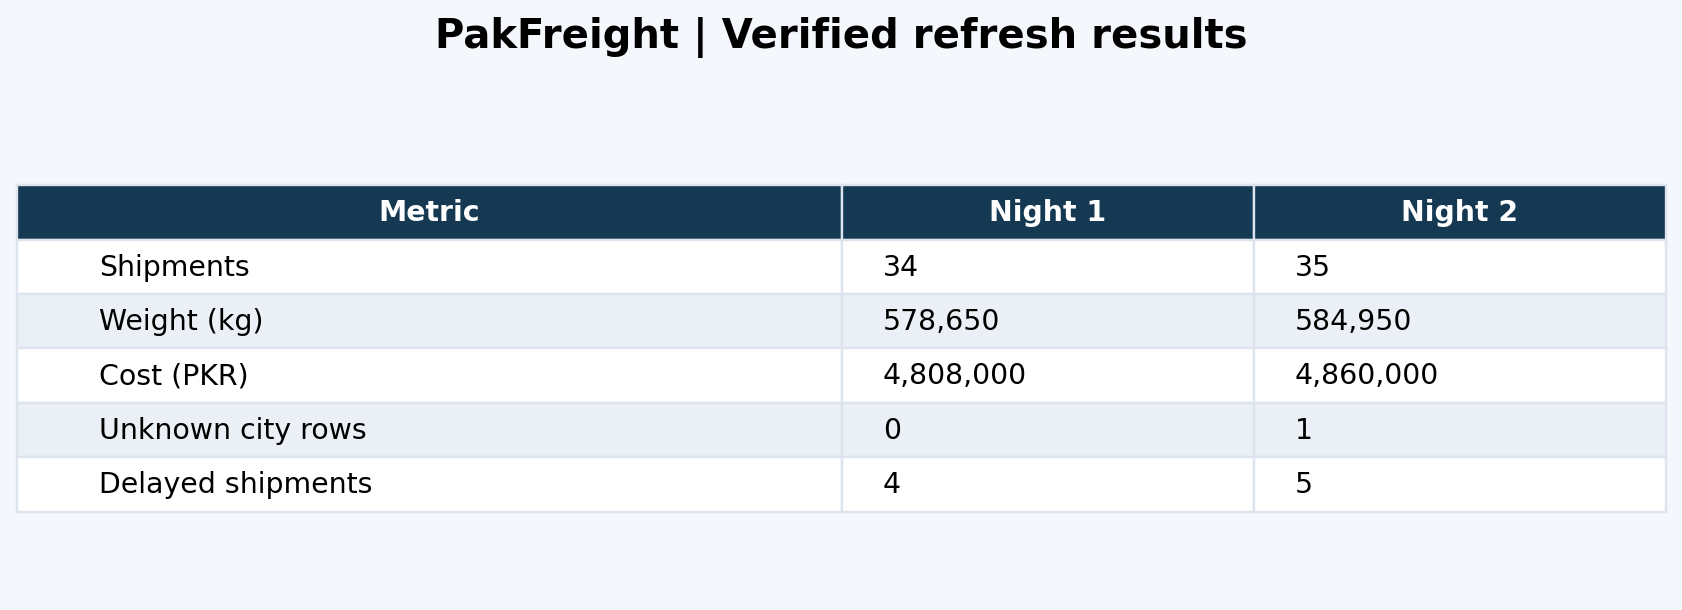

Completed: baseline 8/8; refresh 6/6. Both six-table databases and CSV snapshots exported.


In [8]:
comparison=pd.DataFrame({'Metric':['Shipments','Weight (kg)','Cost (PKR)','Unknown city rows','Delayed shipments'],
 'Night 1':[len(night1['fact']),int(night1['fact'].WeightKG.sum()),int(night1['fact'].FreightCostPKR.sum()),len(night1['unknown']),int(night1['fact'].StatusRaw.eq('Delayed').sum())],
 'Night 2':[len(f),int(f.WeightKG.sum()),int(f.FreightCostPKR.sum()),len(night2['unknown']),int(f.StatusRaw.eq('Delayed').sum())]})
display(comparison)
# Export a reproducible before/after result image (not a Power BI screenshot).
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(10,3.7)); ax.axis('off')
fig.patch.set_facecolor('#f4f7fb')
ax.set_title('PakFreight | Verified refresh results',fontsize=17,fontweight='bold',pad=24)
view=comparison.copy()
for col in ['Night 1','Night 2']: view[col]=view[col].map(lambda x:f'{x:,}')
t=ax.table(cellText=view.values,colLabels=view.columns,cellLoc='left',loc='center',colWidths=[.5,.25,.25]); t.auto_set_font_size(False); t.set_fontsize(12); t.scale(1,1.9)
for (r,c),cell in t.get_celld().items():
    cell.set_edgecolor('#dde4ee'); cell.set_facecolor('#153952' if r==0 else ('#ffffff' if r%2 else '#eaf0f6'))
    if r==0: cell.get_text().set_color('white'); cell.get_text().set_weight('bold')
fig.tight_layout(); fig.savefig(ROOT/'outputs/refresh_before_after.png',dpi=170,bbox_inches='tight'); plt.close(fig)
display(Image(filename=str(ROOT/'outputs/refresh_before_after.png')))
comparison.to_csv(ROOT/'outputs/refresh_comparison.csv',index=False)
print('Completed: baseline 8/8; refresh 6/6. Both six-table databases and CSV snapshots exported.')

## Reproduction and submission notes
- Open `PakFreight_W5_Completed.ipynb` and Run All, or run `python pipeline.py` for ETL outputs.
- Install the packages in `requirements.txt` if your Python environment does not already provide them.
- `outputs/night1/` and `outputs/night2/` contain all six published tables, SQLite databases, and audit results. `outputs/staging/` holds faithful source copies and is not a reporting surface.
- `outputs/refresh_before_after.png` is a generated evidence image of the executed results; the notebook also embeds the result. It is not represented as a screenshot from Power BI.
- The original workbook is included unchanged for reference. All seven tasks are answered here in the requested notebook format. No fictitious team members, roll numbers, Power BI execution or live scheduling are claimed.

**Sources:** supplied `README(8).md`, `TASKS(9).md`, `PowerQuery_Lab_Guide.md`, workbook task sheets and the attached source/dimension files. All reported data values are calculated from those files.